# Lecture 13 notebook: the baseline trend portfolio

This notebook replays Lecture 13. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free and the same as Lecture 12's: the daily prices of Lecture 11's ETFs from Yahoo Finance, the 3-month Treasury bill rate from FRED, and Lecture 12's 36 daily trend streams per market (built by Lecture 12's notebook or here if missing). The regime study of §4.3 also uses long monthly series from FRED and the Kenneth French data library; the futures checks use the capstone futures of Lecture 10 (local, not committed).

By default the notebook builds the baseline's daily returns if they are not there yet, redraws every figure of the lecture as `figures/nb_*.png` from the shipped results, and checks the lecture's mechanics by hand: the baseline rebuilt for one year, minimum variance and equal risk contributions on three speeds, the number of independent bets, and the take-profit rule used in §6. `RUN_ALL` also reruns every analysis (about an hour, one script at a time) and compares the key numbers with the shipped ones. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | |
| 1 | Equal risk at every level: the build, the key chart, the baseline rebuilt for one year | §1 |
| 2 | How weighting methods choose: three speeds in one market by hand, ten methods, 43 markets, resampled weights | §2 |
| 3 | Speeds inside a market: overlap by ratio, equal risk contributions by hand, the blends, the examples and random grids | §3 |
| 4 | Markets and classes: equal risk and equal capital, groups, regimes, the stress test, unstable correlations, losing together | §4 |
| 5 | The total: volatility target and constant leverage | §5 |
| 6 | Today's portfolio in past crises, with the take-profit rule by hand | §6 |
| 7 | Shipped against recomputed; a test of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(SCRIPTS.parents[1] / "12-trend-speeds-by-asset-class" / "scripts"), str(SCRIPTS.parents[1] / "08-filters-and-overlays" / "scripts")]
import l27 as M
L26, L25 = M.L26, M.L25
RUN_ALL = False                                                            # True: also rerun every analysis (about an hour)

SHIPPED = HERE / "results"; WORK = L25.DATA / "l27_results"               # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
for f in SHIPPED.glob("*.json"):                                           # results added to the lecture since WORK was made
    if not (WORK / f.name).exists(): shutil.copy(f, WORK / f.name)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("data:", L25.DATA, "| streams:", L26.OUT / "streams", "| daily results:", M.OUT, "| shipped results:", SHIPPED, "| recomputed results:", WORK)


def run(script, *args, show=False):
    "Run a script of this lecture (or of Lectures 8, 11 and 12) in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time(); path = next(p for p in (SCRIPTS / script, M.REPO / "lectures" / "12-trend-speeds-by-asset-class" / "scripts" / script,
                                              M.REPO / "lectures" / "11-choosing-the-markets" / "scripts" / script,
                                              M.REPO / "lectures" / "08-filters-and-overlays" / "scripts" / script) if p.exists())
    env = {**os.environ, "PORTFOLIO_DATA": str(L25.DATA), "L27_RESULTS": str(WORK), "L27_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(path), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))

data: C:\Users\maxgn\New Trading Models\systematic-trading-notes\data\portfolio | streams: C:\Users\maxgn\New Trading Models\systematic-trading-notes\data\portfolio\l26\streams | daily results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\data\portfolio\l27 | shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\13-the-baseline-trend-portfolio\results | recomputed results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\data\portfolio\l27_results


**The data.** Lecture 11's prices, the bill rate and Lecture 12's streams are fetched or built if missing. The baseline's daily out-of-sample returns, with its rivals, are built once by `l27.py` (about ten minutes).

In [2]:
if not L25.RAW.exists(): run("l25_fetch.py", show=True)
if not L26.RATE.exists(): run("l26_fetch_rate.py", show=True)
if len(list((L26.OUT / "streams").glob("*.parquet"))) < 100: run("l26_streams.py", show=True)
if not (M.OUT / "l27_daily.parquet").exists(): run("l27.py")
close, high, low, dv, rf = L26.load_daily(); D = pd.read_parquet(M.OUT / "l27_daily.parquet")
print(f"{close.shape[1]} ETFs to {close.index.max().date()}; baseline daily returns {D.index.min().date()} to {D.index.max().date()}, Sharpe ratio {L26.sharpe(D['rule']):.3f}")

l25_fetch.py : 399 s
to fetch: 118
SPY 8510
QQQ 6968
MDY 7939
IWM 6660
XLB 7020
XLE 7020
XLF 7020
XLI 7020
XLK 7020
XLP 7020
XLU 7020
XLV 7020
XLY 7020
XLRE 2795
XLC 2117
EWA 7719
EWC 7719
EWD 7719
EWG 7719
EWH 7719
EWI 7719
EWJ 7719
EWK 7719
EWL 7719
EWN 7719
EWO 7719
EWP 7719
EWQ 7719
EWS 7719
EWU 7719
EIS 4692
ENZL 4078
EWT 6641
EWY 6670
EWZ 6627
EWW 7719
EZA 5984
EWM 7719
FXI 5564
ECH 4779
TUR 4692
THD 4690
EPU 4381
EIDO 4160
EPHE 4060
INDA 3720
EPOL 4147
RSX no data
EFA 6345
EEM 5939
VGK 5459
AAXJ 4594
SMH 6655
SOXX 6376
IBB 6481
XBI 5230
ARKG 3030
ICLN 4630
TAN 4680
FAN 4628
LIT 4107
URA 4033
NLR 4847
GDX 5157
XME 5135
OIH 6472
ITB 5168
ITA 5168
PAVE 2440
PHO 5271
WOOD 4630
KWEB 3346
HACK 3022
CIBR 2861
SKYY 3867
CLOU 1910
FINX 2561
ARKK 3030
BOTZ 2561
ROBO 3289
AIQ 2140
IRBO no data
DRIV 2161
BLOK 2217
ESPO 2033
UFO 1913
MJ 2756
SHY 6117
IEI 4996
IEF 6117
TLT 6117
TIP 5775
BWX 4807
BNDX 3387
LQD 6117
HYG 4935
EMB 4759
MBB 4952
BKLN 3953
UUP 4963
UDN 4963
FXE 5267
FXY 4974
FXB 51

l26_fetch_rate.py : 2 s
saved C:\Users\maxgn\New Trading Models\systematic-trading-notes\data\portfolio\DTB3.csv



l26_streams.py : 135 s

Equity: 87 markets, 104 s; Sharpe after 5 bp, 2007 on, median over markets:
           11    17    23    31    43    61    89    127   179   251   359   503
ewma     -0.13 -0.08 -0.04  0.00 -0.01  0.04  0.08  0.09  0.06  0.05  0.01  0.02
breakout -0.09 -0.10 -0.07 -0.04 -0.01  0.02  0.04  0.04  0.07  0.07  0.02 -0.03
return   -0.11 -0.09 -0.07 -0.06  0.01  0.05  0.02  0.06  0.11  0.09  0.02 -0.00

Rates: 7 markets, 13 s; Sharpe after 5 bp, 2007 on, median over markets:
           11    17    23    31    43    61    89    127   179   251   359   503
ewma     -0.07  0.02  0.10  0.21  0.26  0.18  0.24  0.23  0.32  0.29  0.29  0.33
breakout -0.08  0.00  0.15  0.16  0.25  0.21  0.26  0.24  0.25  0.20  0.43  0.29
return   -0.09  0.00  0.02  0.21  0.29  0.20  0.26  0.17  0.31  0.23  0.35  0.20

Credit: 5 markets, 8 s; Sharpe after 5 bp, 2007 on, median over markets:
           11    17    23    31    43    61    89    127   179   251   359   503
ewma      0.12  0.11  0

l27.py : 25 s


116 ETFs to 2026-11-18; baseline daily returns 2013-01-02 to 2026-11-18, Sharpe ratio 0.487


**Running everything.** With `RUN_ALL` the cell below reruns every analysis of the lecture, one at a time: the baseline and its rivals, the tests, the optimisers, the examples and random grids, the speed blends, scaling the total, the correlation regimes, the stress test, the unstable correlations, losing together, and the crisis replay. The regime study downloads long monthly series once; the futures scripts need the capstone futures of Lecture 10 (`data/interim/l11_series99.pkl`) and are skipped without them.

In [3]:
if RUN_ALL:
    for s in ("l27.py", "l27_tests.py", "l27_optimisers.py", "l27_optimisers_many.py", "l27_edge_cases.py", "l27_speeds.py", "l27_leverage.py",
              "l27_regimes.py", "l27_corr_stress.py", "l27_unstable_corr.py", "l27_lose_together.py"): run(s)
    if (M.REPO / "data" / "interim" / "l11_series99.pkl").exists():
        for s in ("l27_futures_test.py", "l27_stress.py"): run(s)
    else: print("capstone futures not found: futures checks skipped")
    D = pd.read_parquet(M.OUT / "l27_daily.parquet")

## 1. Equal risk at every level

The build in one picture (one rule, equal risk, at every level), then the key chart: the correlation of two streams in the same market against the ratio of their speeds, and each class's share of capital and of risk.

l27_build_diagram.py : 8 s


l27_key_chart.py : 6 s
ewma {Interval(1.0, 1.5, closed='right'): 0.93, Interval(1.5, 2.5, closed='right'): 0.84, Interval(2.5, 5.0, closed='right'): 0.65, Interval(5.0, 10.0, closed='right'): 0.43, Interval(10.0, 60.0, closed='right'): 0.22}
breakout {Interval(1.0, 1.5, closed='right'): 0.9, Interval(1.5, 2.5, closed='right'): 0.82, Interval(2.5, 5.0, closed='right'): 0.63, Interval(5.0, 10.0, closed='right'): 0.44, Interval(10.0, 60.0, closed='right'): 0.25}
return {Interval(1.0, 1.5, closed='right'): 0.84, Interval(1.5, 2.5, closed='right'): 0.74, Interval(2.5, 5.0, closed='right'): 0.58, Interval(5.0, 10.0, closed='right'): 0.44, Interval(10.0, 60.0, closed='right'): 0.28}
same speed, different rules 0.88
{'Equity': (np.float64(0.096), np.float64(0.228)), 'Rates': (np.float64(0.467), np.float64(0.185)), 'Credit': (np.float64(0.194), np.float64(0.22)), 'Commodities': (np.float64(0.075), np.float64(0.183)), 'FX': (np.float64(0.168), np.float64(0.184))}



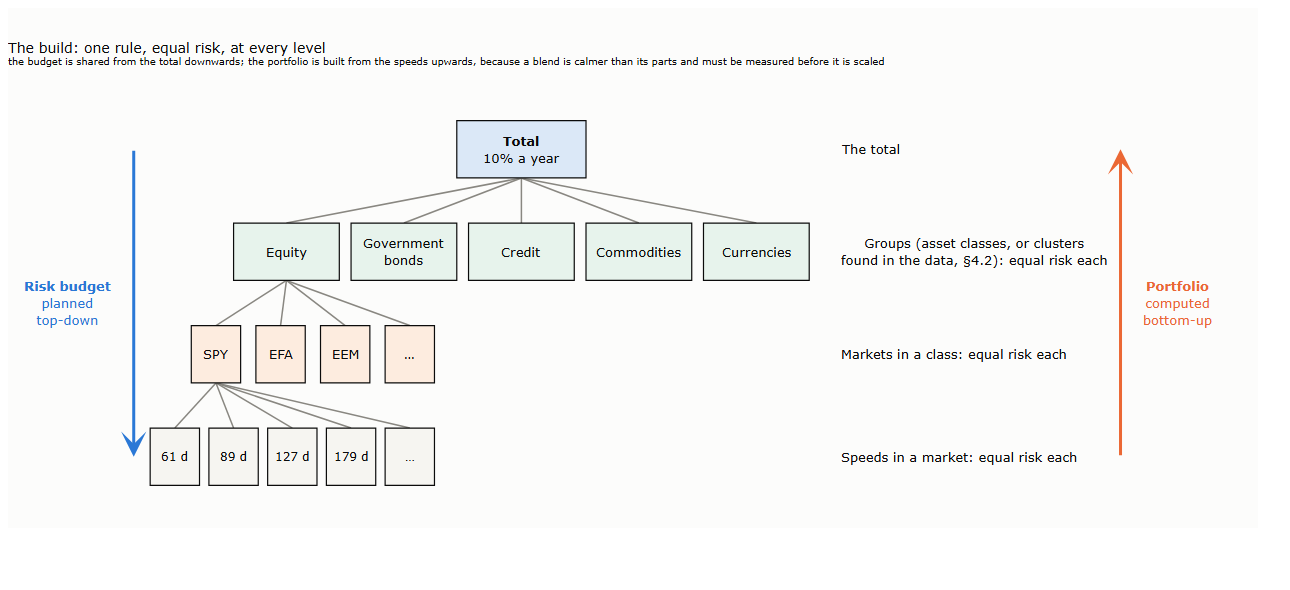

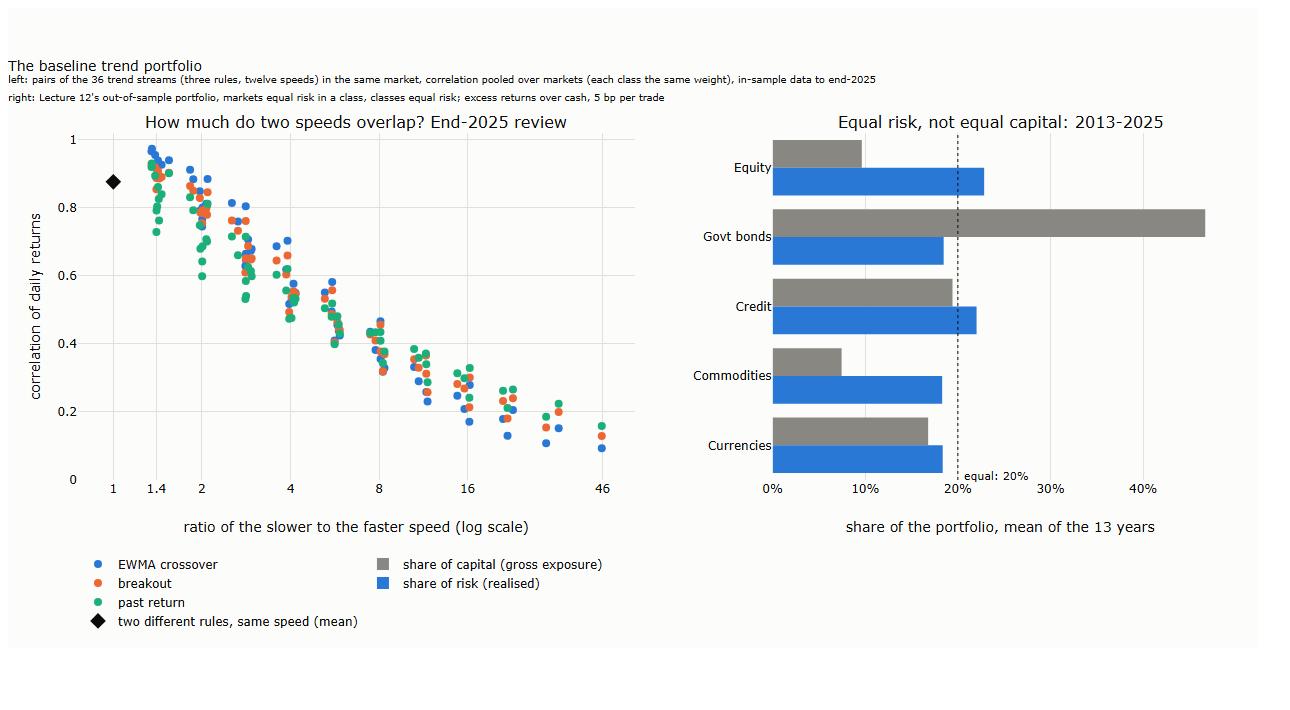

In [4]:
run("l27_build_diagram.py"); run("l27_key_chart.py", show=True)
pictures("27_build", "27_key")

### 1.1 The baseline rebuilt for one year

The baseline in one sentence: speeds at equal weight in each market, markets at equal risk in each class, classes at equal risk, the total scaled to 10% on the past three years. Rebuilt here for 2026, chosen at the end-2025 review, from Lecture 12's net stream returns, against the stored daily returns.

In [5]:
NET = {}
def net(t):
    if t not in NET: NET[t] = L26.net(pd.read_parquet(L26.OUT / "streams" / f"{t}.parquet")[L26.START:])
    return NET[t]
y = 2025; held = [k for k, v in M.SEL[str(y)]["weights"]["one_set"].items() if v >= 0.2]; uni = M.UNI[str(y)]["sc_div"]
hist, nxt = slice(f"{y - 2}-01-01", f"{y}-12-31"), slice(f"{y + 1}-01-01", f"{y + 1}-12-31"); day = M.TARGET / np.sqrt(252)
R = pd.DataFrame({t: net(t)[held].mean(axis=1) for k in uni for t in uni[k]})          # step 1: speeds at equal weight
a = 1 / R.loc[hist].std()                                                              # step 2: markets at equal risk
cls = {k: R[m].mul(a[m]).mean(axis=1) for k, m in uni.items()}
cls = {k: v * day / v.loc[hist].std() for k, v in cls.items()}                        # step 3: classes at equal risk
U = pd.DataFrame(cls).mean(axis=1); base = (U * day / U.loc[hist].std()).loc[nxt]       # step 4: total at 10%
print(f"{len(held)} streams, {sum(map(len, uni.values()))} markets in {len(uni)} classes; largest daily difference from the stored baseline: {(base - D['rule'].reindex(base.index)).abs().max():.1e}")

20 streams, 20 markets in 5 classes; largest daily difference from the stored baseline: 2.7e-09


## 2. How weighting methods choose

### 2.1 Three speeds in one market, by hand

SPY's EWMA crossover at 43, 89 and 179 days, with the correlations measured at the end of 2025. Minimum variance, long only, solved by brute force over a grid of weights, and equal risk contributions by iteration, against the weights stored by `l27_optimisers.py`. With nearly equal volatilities, minimum variance drops the middle speed: it overlaps most with the other two.

In [6]:
O = result("optimisers.json"); Cs = np.array(O["SPY"]["corr_end2025"]); stored = O["SPY"]["weights"]["2025"]
grid = [(a, b, 1 - a - b) for a in np.linspace(0, 1, 201) for b in np.linspace(0, 1, 201) if a + b <= 1 + 1e-12]
mv = min(grid, key=lambda w: np.array(w) @ Cs @ np.array(w))                             # minimum variance on the correlation matrix
w = np.ones(3) / 3
for _ in range(500): w = 0.5 * w + 0.5 * (1 / (Cs @ w)) / (1 / (Cs @ w)).sum()          # equal risk contributions, fixed-point iteration
print("correlations, end 2025:\n", Cs.round(3))
print(f"minimum variance by hand: {np.round(mv, 2)}; stored: {np.round(stored['Minimum variance, long only'], 2)}")
print(f"equal risk contributions by hand: {w.round(3)}; stored: {np.round(stored['Equal risk contributions'], 3)}; risk shares {(w * (Cs @ w) / (w @ Cs @ w)).round(3)}")

correlations, end 2025:
 [[1.    0.855 0.576]
 [0.855 1.    0.804]
 [0.576 0.804 1.   ]]
minimum variance by hand: [0.5 0.  0.5]; stored: [0.5 0.  0.5]
equal risk contributions by hand: [0.341 0.312 0.347]; stored: [0.341 0.312 0.347]; risk shares [0.333 0.333 0.333]


### 2.2 Ten methods on the same three speeds

The weights each method chose at the end-2025 review, and how they did out of sample, 2013-2026, for SPY, oil (USO) and long Treasuries (TLT).

In [7]:
display(pd.DataFrame({k: np.round(v, 2) for k, v in stored.items()}, index=["43 days", "89 days", "179 days"]).T)
display(pd.DataFrame({t: {k: v["sharpe"] for k, v in O[t]["oos"].items()} for t in O}).round(3))

,43 days,89 days,179 days
Equal weight,0.33,0.33,0.33
Equal risk contributions,0.34,0.31,0.35
"Minimum variance, long only",0.50,0.00,0.50
"Minimum variance, shorts",0.68,-0.33,0.64
"Maximum Sharpe, long only",0.00,0.00,1.00
"Maximum Sharpe, shorts",-0.35,-0.34,1.69
"Maximum Sharpe, shrunk, long only",0.50,0.00,0.50
HRP,0.26,0.26,0.48
NCO (equal risk contributions),0.25,0.25,0.49
"Spectral risk parity, long only",0.00,0.00,1.00


,SPY,USO,TLT
Equal weight,0.353,0.273,0.280
Equal risk contributions,0.353,0.271,0.280
"Minimum variance, long only",0.338,0.273,0.270
"Minimum variance, shorts",0.310,0.279,0.257
"Maximum Sharpe, long only",0.455,0.266,0.224
"Maximum Sharpe, shorts",0.303,0.147,0.102
"Maximum Sharpe, shrunk, long only",0.329,0.273,0.270
HRP,0.386,0.237,0.272
NCO (equal risk contributions),0.388,0.234,0.271
"Spectral risk parity, long only",0.455,0.102,0.215


### 2.3 Forty-three markets, and weights under resampling

Each method's Sharpe ratio difference to equal risk contributions across the 43 markets with enough history (median, quartiles, how many lie outside their 90% band), and how far the weights move when history is resampled.

,median,q1,q3,share_above,above_band,below_band
Equal weight,0.001,-0.001,0.003,0.651,10.0,1.0
Equal risk contributions,0.000,0.000,0.000,0.000,0.0,0.0
"Minimum variance, long only",-0.015,-0.044,0.012,0.349,1.0,13.0
"Minimum variance, shorts",-0.026,-0.069,0.013,0.337,1.0,14.0
"Maximum Sharpe, long only",-0.010,-0.059,0.076,0.465,8.0,2.0
"Maximum Sharpe, shorts",-0.042,-0.208,0.160,0.419,5.0,8.0
"Maximum Sharpe, shrunk, long only",-0.017,-0.056,0.010,0.349,2.0,12.0
HRP,0.001,-0.016,0.020,0.523,4.0,1.0
NCO (equal risk contributions),0.001,-0.017,0.021,0.523,4.0,1.0
"Spectral risk parity, long only",-0.005,-0.089,0.077,0.453,1.0,2.0


l27_optimisers_charts.py : 5 s


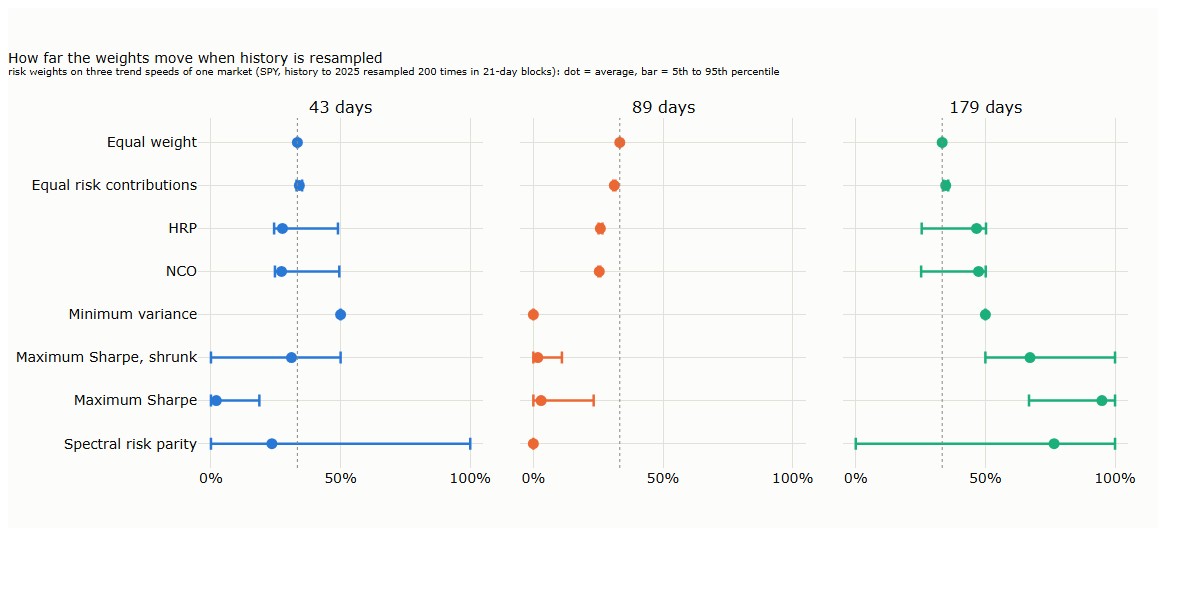

In [8]:
OM = result("optimisers_many.json")
display(pd.DataFrame(OM["summary"]).T[["median", "q1", "q3", "share_above", "above_band", "below_band"]].round(3))
run("l27_optimisers_charts.py")
pictures("27_opt_resampled")

## 3. Speeds inside a market

### 3.1 Overlap by speed ratio

The pooled correlation of the 36 streams at the end-2025 review (each class the same weight), averaged over pairs of the same rule by ratio of speeds, and over different rules at the same speed.

In [9]:
S = result("speeds.json"); Cr = pd.DataFrame(S["reviews"]["2025"]["corr"])
pairs = [(int(b.split("_")[1]) / int(a.split("_")[1]), a.split("_")[0], Cr.loc[a, b]) for r in L26.RULES for a, b in combinations([f"{r}_{h}" for h in L26.SPEEDS], 2)]
P = pd.DataFrame(pairs, columns=["ratio", "rule", "corr"]); P["ratio band"] = pd.cut(P.ratio, [1, 1.5, 2.5, 5, 10, 60], labels=["1.4", "2", "3-4", "6-8", "11-46"])
display(P.pivot_table(index="rule", columns="ratio band", values="corr", aggfunc="mean", observed=True).round(2))
same = [Cr.loc[f"{a}_{h}", f"{b}_{h}"] for h in (61, 89, 127, 179, 251, 359) for a, b in combinations(L26.RULES, 2)]
print(f"different rules at the same speed (61-359 days): {np.mean(same):.2f}")

ratio band,1.4,2,3-4,6-8,11-46
rule,,,,,
breakout,0.90,0.82,0.63,0.44,0.25
ewma,0.93,0.84,0.65,0.43,0.22
return,0.84,0.74,0.58,0.44,0.28


different rules at the same speed (61-359 days): 0.88


### 3.2 Equal risk contributions and independent bets, by hand

For the held streams at the end-2025 review: the weights of `l27_speeds.erc`, then each stream's risk contribution $w_i (Cw)_i$ computed by hand (they should be equal), and the number of independent bets $(\sum_i w_i)^2 / w^\top C w$ for equal weights and for equal risk contributions.

In [10]:
import l27_speeds as SP
held = S["reviews"]["2025"]["held"]; Ch = Cr.loc[held, held].to_numpy()
w, _ = SP.erc(Ch, np.ones(len(held))); rc = w * (Ch @ w); rc = rc / rc.sum(); eq = np.ones(len(held)) / len(held)
print(f"weights {w.min():.3f} to {w.max():.3f} (equal: {1 / len(held):.3f}); risk contributions {rc.min():.4f} to {rc.max():.4f} (equal: {1 / len(held):.4f})")
print(f"stored weights match: {np.allclose(w, pd.Series(S['reviews']['2025']['weights']['correlation'])[held].to_numpy(), atol=1e-3)}")
print(f"independent bets: equal weights {eq.sum() ** 2 / (eq @ Ch @ eq):.2f}, equal risk contributions {w.sum() ** 2 / (w @ Ch @ w):.2f}; average pairwise correlation {Ch[np.triu_indices(len(held), 1)].mean():.2f}")

weights 0.045 to 0.058 (equal: 0.050); risk contributions 0.0500 to 0.0500 (equal: 0.0500)
stored weights match: True
independent bets: equal weights 1.39, equal risk contributions 1.41; average pairwise correlation 0.70


### 3.3 The blends out of sample

Sharpe ratio after costs 2013-2026 for each blend, and the streams maximum Sharpe ratio picked at three reviews.

In [11]:
display(pd.Series(S["oos"]).rename("Sharpe ratio, 2013-2026").round(3).to_frame())
for y in ("2012", "2018", "2025"):
    ms = {k: round(v, 2) for k, v in S["reviews"][y]["weights"]["max_sharpe"].items() if v > 0.01}
    print(f"{y}: maximum Sharpe ratio holds {len(ms)} of {len(S['reviews'][y]['held'])} streams: {ms}")

,"Sharpe ratio, 2013-2026"
equal,0.486
correlation,0.482
max_sharpe,0.455
cost_0.2,0.483
cost_0.3,0.482
cost_0.5,0.482


2012: maximum Sharpe ratio holds 5 of 19 streams: {'ewma_89': 0.22, 'ewma_179': 0.5, 'ewma_359': 0.07, 'breakout_359': 0.1, 'return_61': 0.1}
2018: maximum Sharpe ratio holds 3 of 17 streams: {'ewma_89': 0.55, 'breakout_61': 0.06, 'breakout_127': 0.39}
2025: maximum Sharpe ratio holds 5 of 20 streams: {'ewma_89': 0.58, 'breakout_61': 0.08, 'breakout_359': 0.15, 'return_179': 0.03, 'return_359': 0.16}


### 3.4 The examples: grids, even speeds, a bunch, and random grids

Risk shares by region of speed for each example of the lecture (three even speeds, a bunch of near-copies, a near-copy), the spacing patterns, and 1,000 random grids: how far each method's risk split is from fair, and how far the weights move when one correlation moves by 0.01. Then the stability chart.

Even: 50, 100, 200


,weights,risk by region,largest move
Equal weight,"[0.3333, 0.3333, 0.3333]","[0.325, 0.35, 0.325]",None
Equal risk contributions,"[0.3408, 0.3184, 0.3408]","[0.333, 0.333, 0.333]",None
"Minimum variance, long only","[0.4481, 0.1038, 0.4481]","[0.448, 0.104, 0.448]",None
Grouped by region,"[0.3333, 0.3333, 0.3333]","[0.325, 0.35, 0.325]",None


Bunched: 50, 60, 70 and 200


,weights,risk by region,largest move
Equal weight,"[0.25, 0.25, 0.25, 0.25]","[0.782, 0.218]",0.0
Equal risk contributions,"[0.2447, 0.2373, 0.2379, 0.2802]","[0.75, 0.25]",0.0003
"Minimum variance, long only","[0.4103, 0.0253, 0.0897, 0.4747]","[0.525, 0.475]",0.0554
Grouped by region,"[0.1704, 0.1667, 0.1698, 0.493]","[0.5, 0.5]",0.0003


A near-copy: 50, 50, 100, 200


,weights,risk by region,largest move
Equal weight,"[0.25, 0.25, 0.25, 0.25]","[0.517, 0.255, 0.228]",0.0
Equal risk contributions,"[0.2426, 0.2426, 0.2442, 0.2705]","[0.5, 0.25, 0.25]",0.0003
"Minimum variance, long only","[0.2265, 0.2265, 0.0994, 0.4475]","[0.453, 0.099, 0.448]",0.0045
Grouped by region,"[0.1669, 0.1669, 0.3331, 0.3331]","[0.325, 0.35, 0.325]",0.0003


Two bunches: 50, 55, 60 and 180, 200, 220


,weights,risk by region,largest move
Equal weight,"[0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]","[0.5, 0.5]",0.0
Equal risk contributions,"[0.1692, 0.1657, 0.1647, 0.1648, 0.166, 0.1695]","[0.5, 0.5]",0.0002
"Minimum variance, long only","[0.3982, 0.0135, 0.0869, 0.0883, 0.0149, 0.3982]","[0.499, 0.501]",0.0906
Grouped by region,"[0.1672, 0.1653, 0.1671, 0.1676, 0.1654, 0.1674]","[0.5, 0.5]",0.0003


,Equal weight,Equal risk contributions,Grouped by third
Same ratio (geometric),"[0.323, 0.354, 0.323]","[0.333, 0.333, 0.333]","[0.323, 0.355, 0.323]"
Same day difference (arithmetic),"[0.133, 0.344, 0.523]","[0.167, 0.333, 0.5]","[0.309, 0.358, 0.332]"
"U-shaped: dense at both ends, none in the middle","[0.5, 0.0, 0.5]","[0.5, 0.0, 0.5]","[0.5, 0.0, 0.5]"
Erratic,"[0.525, 0.176, 0.299]","[0.5, 0.167, 0.333]","[0.334, 0.352, 0.314]"


,median_gap,p90_gap,median_move,p90_move,median_whole,p90_whole
Equal weight,0.186,0.360,0.000,0.000,0.169,0.279
Equal risk contributions,0.167,0.333,0.000,0.000,0.157,0.260
"Minimum variance, long only",0.225,0.257,0.031,0.054,0.265,0.328
"HRP, as published",0.180,0.292,0.000,0.001,0.156,0.263
Grouped by third,0.019,0.024,0.000,0.000,0.097,0.145


l27_bunch_stability_chart.py : 6 s


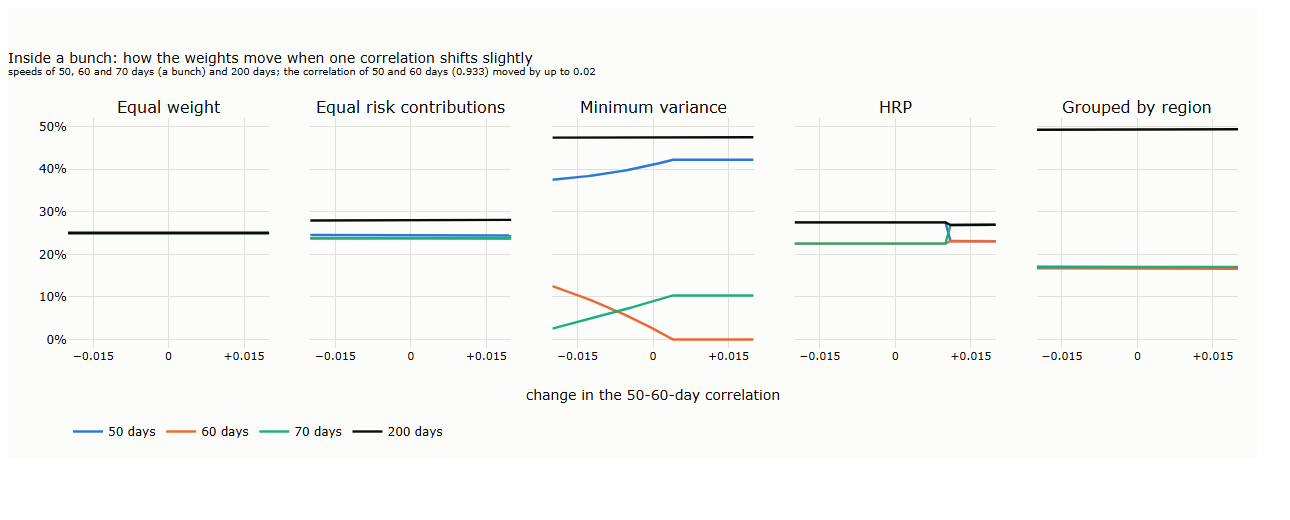

In [12]:
E = result("edge_cases.json")
for case, methods in E.items():
    print(case); display(pd.DataFrame({m: {"weights": v["weights"], "risk by region": v["region_risk"], "largest move": v["max_move"]} for m, v in methods.items()}).T)
SPC = result("spacing.json")
display(pd.DataFrame({k: {m: v[m] for m in v if m not in ("speeds", "per_third")} for k, v in SPC.items()}).T)
display(pd.DataFrame(result("random_grids.json")).T.round(3))
run("l27_bunch_stability_chart.py")
pictures("27_bunch_stability")

## 4. Markets and classes

### 4.1 Equal risk, not equal capital; 4.2 classes or groups found in the data

Equal risk against equal capital inside the classes, and the classes against groups found in the data, from the daily returns; then the tests and each class's share of capital and of risk.

In [13]:
dd = lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()
gross = D.gross_U * D.ctot
display(pd.DataFrame({"equal risk (baseline)": {"Sharpe": L26.sharpe(D.rule), "volatility": D.rule.std() * np.sqrt(252), "worst drawdown": dd(D.rule), "gross, median": gross.median()},
                      "equal capital": {"Sharpe": L26.sharpe(D.equal_capital), "volatility": D.equal_capital.std() * np.sqrt(252), "worst drawdown": dd(D.equal_capital), "gross, median": D.gross_eqcap.median()},
                      "groups, Ward": {"Sharpe": L26.sharpe(D.ward), "volatility": D.ward.std() * np.sqrt(252), "worst drawdown": dd(D.ward)},
                      "groups, average linkage": {"Sharpe": L26.sharpe(D.groups), "volatility": D.groups.std() * np.sqrt(252), "worst drawdown": dd(D.groups)}}).T.round(3))
print(f"correlation of daily returns, equal capital with the baseline: {D.rule.corr(D.equal_capital):.3f}")
X = result("tests.json"); display(pd.DataFrame({k: {"difference": v["diff"], "band 5%": v["ci90"][0], "band 95%": v["ci90"][1]} for k, v in X["tests"].items()}).T.round(3))
print("passes Benjamini-Hochberg:", {k: v for k, v in X["bh"].items()})
L = result("leverage.json"); sh = L["class_shares"]
display(pd.DataFrame({k: {"capital": np.mean([sh[y][k]["capital"] for y in sh]), "risk": np.mean([sh[y][k]["risk"] for y in sh])} for k in L26.CLASSES}).T.round(3))
CS = result("corr_stress.json")
display(pd.DataFrame({k: {m: v.get(m) for m in ("median_agreement", "accepted", "bets_flat", "bets_split")} for k, v in CS["split"].items()}).T)

,Sharpe,volatility,worst drawdown,"gross, median"
equal risk (baseline),0.487,0.107,-0.222,3.386
equal capital,0.442,0.105,-0.244,2.165
"groups, Ward",0.517,0.108,-0.210,NaN
"groups, average linkage",0.522,0.109,-0.248,NaN


correlation of daily returns, equal capital with the baseline: 0.981


,difference,band 5%,band 95%
aware_sharpe,-0.019,-0.140,0.103
aware_drawdown,-0.056,-0.062,0.043
aware_risk_spread,0.087,0.027,0.137
ward_sharpe,0.036,-0.120,0.183
ward_drawdown,0.012,-0.022,0.113
ward_risk_spread,0.035,-0.007,0.075
groups_sharpe,0.046,-0.152,0.249
groups_drawdown,-0.026,-0.041,0.134
groups_risk_spread,0.050,-0.017,0.122


passes Benjamini-Hochberg: {'aware_risk_spread': False, 'ward_risk_spread': False, 'ward_drawdown': False, 'ward_sharpe': False, 'aware_sharpe': False, 'aware_drawdown': False}


,capital,risk
Equity,0.096,0.228
Rates,0.467,0.185
Credit,0.194,0.220
Commodities,0.075,0.183
FX,0.168,0.184


,median_agreement,accepted,bets_flat,bets_split
Equity,0.432432,False,5.203119,5.101134
Rates,1.0,True,1.613422,1.589057
Credit,None,False,None,None
Commodities,1.0,True,3.06007,2.766379
FX,1.0,True,1.524629,1.598854


### 4.3 When correlations across classes change regime

Monthly class returns and their trend streams, 1973-2024, in eight regime windows: the stock-bond correlation of the assets and of the trend streams, the average absolute correlation, and the chart.

,months,stock_bond_assets,stock_bond_trend,avg_abs_assets,avg_abs_trend
1973-1982 high inflation,120.0,0.16,-0.02,0.20,0.07
1983-1999 disinflation,204.0,0.11,0.08,0.17,0.06
2000-2002 equity bear market,36.0,-0.43,0.39,0.30,0.18
2003-2006 calm,48.0,-0.03,-0.15,0.25,0.17
2007-2009 financial crisis,36.0,-0.34,-0.03,0.42,0.26
2010-2019 low rates,120.0,-0.45,-0.23,0.29,0.10
2020 pandemic,11.0,-0.71,-0.66,0.68,0.46
2022-2024 inflation's return,36.0,0.26,-0.15,0.36,0.19
2023-2025 the baseline's three years,24.0,0.19,-0.42,0.40,0.19


l27_regimes_chart.py : 4 s


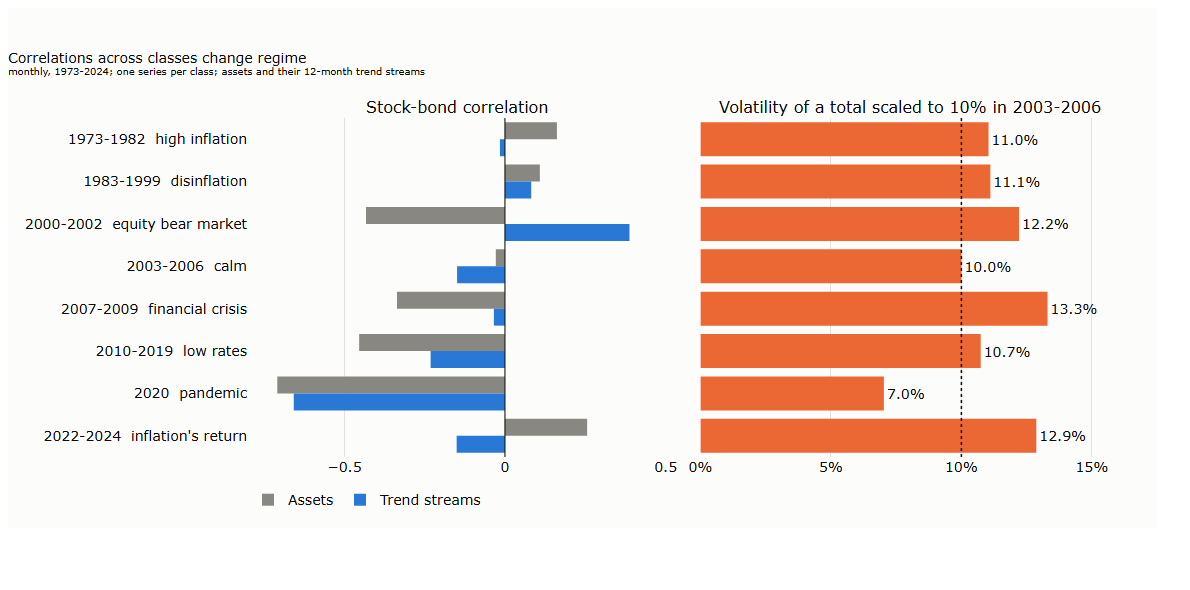

In [14]:
G = result("regimes.json")
display(pd.DataFrame({k: {m: v[m] for m in ("months", "stock_bond_assets", "stock_bond_trend", "avg_abs_assets", "avg_abs_trend")} for k, v in G["windows"].items()}).T.round(2))
run("l27_regimes_chart.py")
pictures("27_regimes")

### 4.4 The correlations to assume, and a stress test

The baseline's 10% total under each correlation scenario: what the same positions would have carried.

,"volatility of the 10% book, %"
"Measured, 2023-2025 (the target)",10.0
Calm (2017),10.5
Average (2008-2025),9.7
"Crisis (highest of 2008-09, 2020, 2022)",15.6
Crisis window 2008-2009,11.5
Crisis window 2020,8.0
Crisis window 2022,12.4
Every correlation at 1 (bound),24.6


l27_corr_stress_chart.py : 3 s


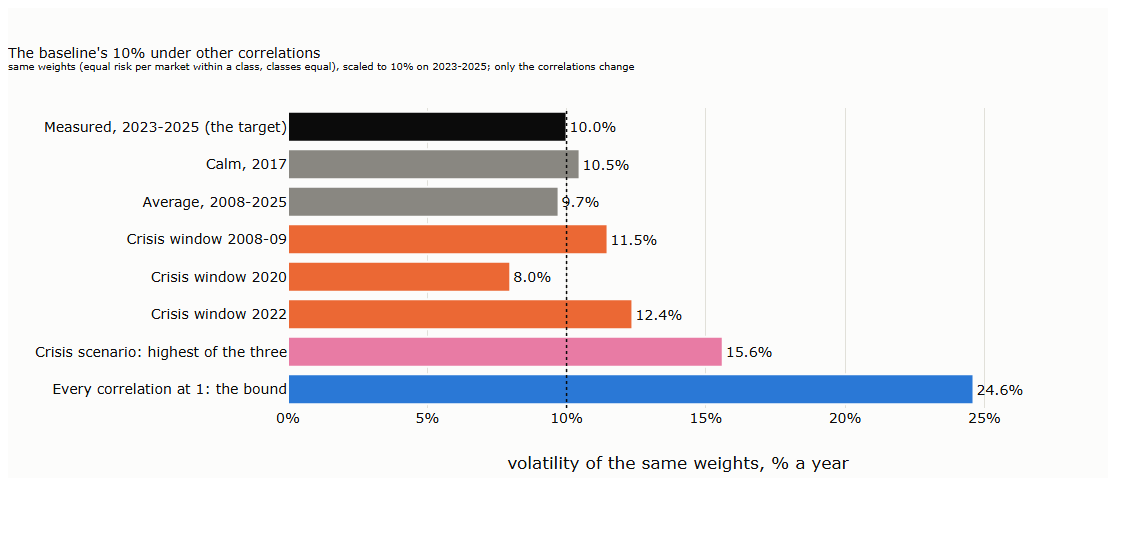

In [15]:
display(pd.Series(CS["stress_total_pct"]).rename("volatility of the 10% book, %").round(1).to_frame())
run("l27_corr_stress_chart.py")
pictures("27_corr_stress")

### 4.5 Weighing when correlations are unstable

Six ways of weighing the five classes, each applied in the eight regimes: the risk the 10% book would have carried in its worst and best regime.

l27_unstable_corr.py : 5 s


,worst,best,worst regime,weight: Equity,weight: Government bonds,weight: Credit,weight: Commodities,weight: Dollar
Equal risk (no correlations),0.118705,0.062773,2007-2009 financial crisis,0.2,0.2,0.2,0.2,0.2
Structured: one average correlation,0.118705,0.062773,2007-2009 financial crisis,0.2,0.2,0.2,0.2,0.2
"Equal risk contributions, blended matrix",0.118391,0.062135,2007-2009 financial crisis,0.196717,0.204265,0.20236,0.205504,0.191154
"Minimum variance, blended matrix",0.118061,0.061372,2007-2009 financial crisis,0.193193,0.208827,0.206654,0.211714,0.179611
"Equal risk contributions, crisis matrix",0.114909,0.062775,2007-2009 financial crisis,0.190464,0.205632,0.170767,0.252351,0.180786
Min-max over the regimes,0.109623,0.061061,2000-2002 equity bear market,0.228687,0.203128,0.118412,0.308169,0.141603


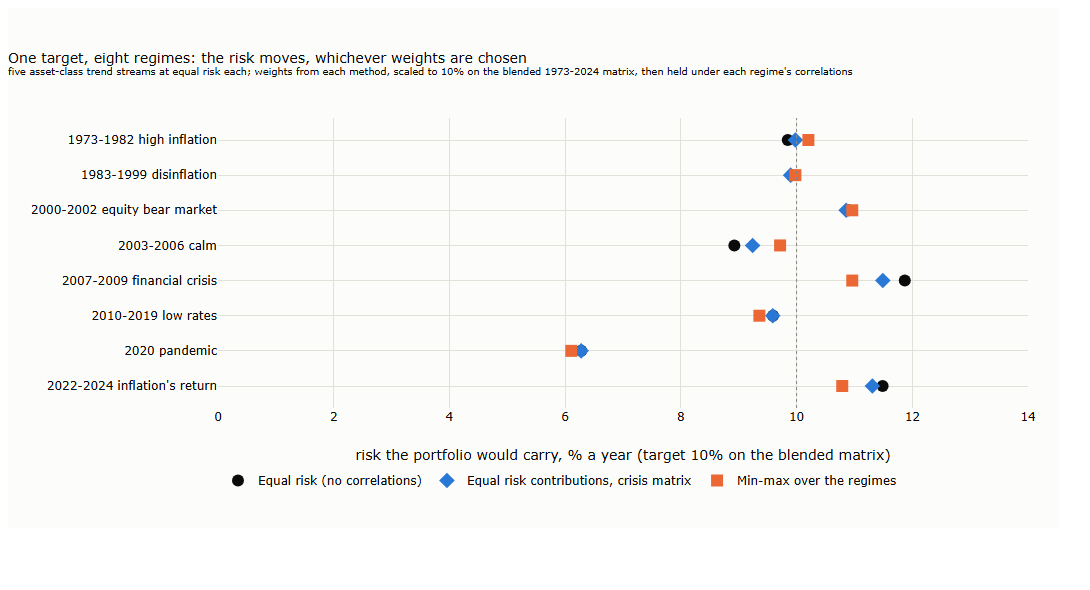

In [16]:
run("l27_unstable_corr.py")
U = result("unstable_corr.json")
display(pd.DataFrame({k: {"worst": v["worst"], "best": v["best"], "worst regime": v["worst_window"]} | {f"weight: {c}": v["weights"][c] for c in U["classes"]} for k, v in U["methods"].items()}).T.round(3))
pictures("27_unstable_corr")

### 4.6 Is correlation that important for a trend book? Losing together

How often four or more of the five class trend streams lose in the same month, against what independence would give; and their correlation in down and up months.

In [17]:
LT = result("lose_together.json")
display(pd.Series({k: v for k, v in LT.items() if not isinstance(v, (dict, list))}).to_frame("value"))

,value
months,600
first,1975-01-31
last,2024-12-31
share_4plus_lose,0.163333
share_4plus_lose_chance,0.143742
p_lose,0.03
share_4plus_gain,0.273333
share_4plus_gain_chance,0.237115
p_gain,0.0
corr_all,0.04307


## 5. The total

Volatility target against constant leverage: the chart, the profile and the Sharpe ratio difference; then the daily rescaling lesson.

l27_charts.py : 6 s


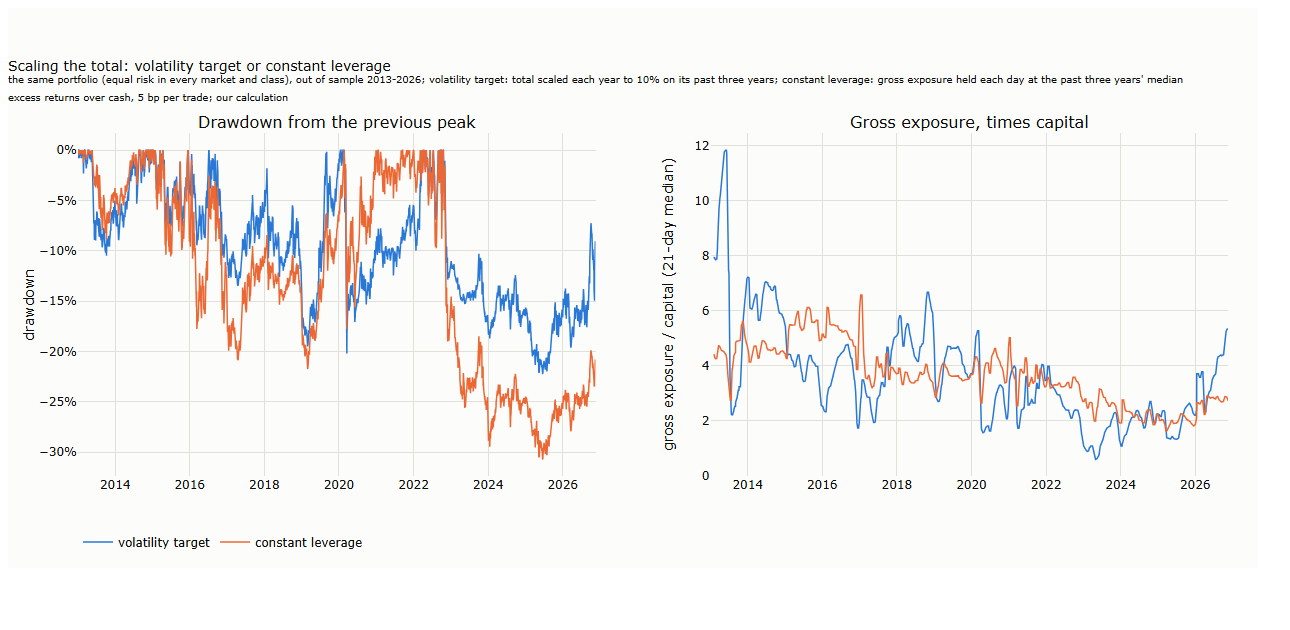

,volatility target,constant leverage
sharpe,0.486,0.390
return_a_year,0.052,0.048
vol,0.107,0.124
vol_3m_low,0.057,0.057
vol_3m_high,0.156,0.229
worst_month,-0.097,-0.146
worst_drawdown,-0.222,-0.307
gross_median,3.380,3.596
gross_low,1.321,1.951
gross_high,6.912,5.579


Sharpe difference, constant leverage minus volatility target: {'diff': np.float64(-0.096), 'ci90': array([-0.25,  0.06])}
scaled daily on today's positions: Sharpe 0.46, volatility 16.2%; 2023: -15.3% against -6.3% for the baseline


In [18]:
run("l27_charts.py")
pictures("27_total")
display(pd.DataFrame(L["profile"]).round(3))
print("Sharpe difference, constant leverage minus volatility target:", {k: np.round(v, 3) for k, v in L["sharpe_difference"].items()})
yr = lambda x, y: (1 + x.loc[str(y)]).prod() - 1
print(f"scaled daily on today's positions: Sharpe {L26.sharpe(D.vol_daily):.2f}, volatility {D.vol_daily.std() * np.sqrt(252):.1%}; 2023: {yr(D.vol_daily, 2023):+.1%} against {yr(D.rule, 2023):+.1%} for the baseline")

## 6. Today's portfolio in past crises

The end-2025 portfolio replayed through each S&P 500 fall of more than 15%, with and without the take-profit of Lecture 8 §4.8.

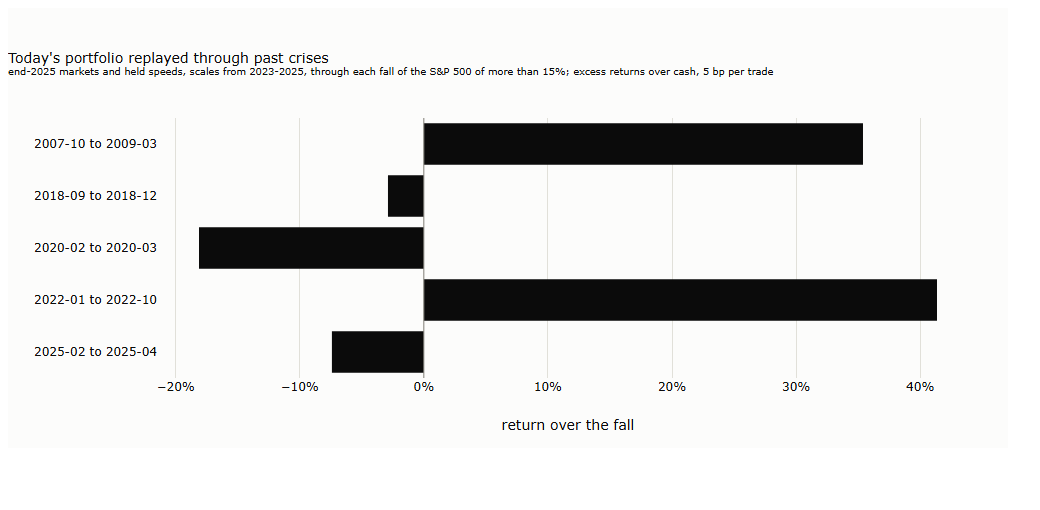

,S&P 500,markets,return,with take-profit 4,drawdown,worst day,class: Equity,class: Rates,class: Credit,class: Commodities,class: FX
2000-03 to 2002-10,-0.491469,5 of 20,0.062996,0.063553,-0.060982,-0.017864,0.062996,NaN,NaN,NaN,NaN
2007-10 to 2009-03,-0.567754,19 of 20,0.353895,0.375085,-0.13142,-0.07203,0.059388,0.088761,0.026844,0.132766,0.046135
2018-09 to 2018-12,-0.197782,20 of 20,-0.028916,-0.023884,-0.070598,-0.03126,-0.024336,-0.02325,0.011762,-0.001947,0.008855
2020-02 to 2020-03,-0.33925,20 of 20,-0.181208,-0.125373,-0.235097,-0.07259,-0.084269,0.005131,-0.16361,0.079841,-0.018302
2022-01 to 2022-10,-0.254251,20 of 20,0.413541,0.333989,-0.106364,-0.038323,-0.036928,0.130784,0.098068,0.044039,0.177577
2025-02 to 2025-04,-0.189022,20 of 20,-0.074099,-0.071252,-0.074691,-0.013645,-0.008484,-0.013698,-0.028178,0.000517,-0.024256


In [19]:
pictures("27_crisis_today")
ST = result("stress.json")
pd.DataFrame({f"{e['peak'][:7]} to {e['trough'][:7]}": {"S&P 500": e["spx"], "markets": f"{e['plain']['markets']} of {e['plain']['of']}", "return": e["plain"]["ret"], "with take-profit 4": e["take-profit 4"]["ret"],
              "drawdown": e["plain"]["drawdown"], "worst day": e["plain"]["worst_day"]} | {f"class: {k}": v for k, v in e["plain"]["by_class"].items()} for e in ST["episodes"]}).T

**The take-profit rule, by hand.** SPY's EWMA crossover at 89 days with a take-profit at k = 4, written as a plain Python loop: the open gain since the signal last changed, in units of daily volatility at entry times the square root of the speed; flat above four units until the signal changes. Against the compiled `run` of Lecture 8's `takeprofit.py`.

In [20]:
import takeprofit as TP
t, h, k = "SPY", 89, 4.0
c = close[t].dropna(); x = L26.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf)[0]
r = x.pct_change().fillna(0).to_numpy(); vol = np.sqrt((x.pct_change() ** 2).ewm(span=L26.VOL_SPAN, min_periods=60).mean() * 252).to_numpy()
sig = L26.signals(x.to_frame("x"), x.to_frame("x"), x.to_frame("x"), h)["ewma"]["x"].to_numpy().astype(float)
pos, prev, gain, unit, flat, out, exits = 0.0, 0.0, 0.0, np.nan, False, np.zeros(len(r)), 0
for i in range(1, len(r)):
    out[i] = pos * r[i]; s = 0.0 if (np.isnan(sig[i]) or np.isnan(vol[i])) else sig[i]
    if s != prev: flat, gain, unit, prev = False, 0.0, vol[i] / np.sqrt(252) * np.sqrt(h), s      # a new trade
    else:
        gain += s * r[i]
        if not flat and gain > k * unit: flat, exits = True, exits + 1                             # take the profit
    target = 0.0 if (flat or s == 0 or np.isnan(vol[i])) else s * 0.10 / vol[i]
    new = pos + 0.1 * (target - pos); out[i] -= 5e-4 * abs(new - pos); pos = new
lib = TP.run(sig, r, vol, float(h), k, False, L26.LAMBDA, L26.VOL_TARGET, L26.COST_BP / 1e4)
print(f"{exits} take-profits; largest daily difference from the library: {np.abs(out - lib).max():.1e}")

4 take-profits; largest daily difference from the library: 0.0e+00


## 7. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped results. With the same download they match exactly; a later download can differ slightly, since Yahoo revises adjusted prices when funds pay distributions.

In [21]:
rows = [dict(number=f"Sharpe, {v}", shipped=result("portfolios.json", SHIPPED)["summary"][v]["sharpe"], recomputed=result("portfolios.json")["summary"][v]["sharpe"])
        for v in ("rule", "equal_capital", "constant_leverage", "ward")]
rows += [dict(number=f"speed blend, {v}", shipped=result("speeds.json", SHIPPED)["oos"][v], recomputed=result("speeds.json")["oos"][v]) for v in ("correlation", "max_sharpe")]
rows += [dict(number=f"stress, {v}", shipped=result("corr_stress.json", SHIPPED)["stress_total_pct"][v], recomputed=result("corr_stress.json")["stress_total_pct"][v])
         for v in ("Crisis (highest of 2008-09, 2020, 2022)", "Every correlation at 1 (bound)")]
pd.DataFrame(rows).round(4)

,number,shipped,recomputed
0,"Sharpe, rule",0.4862,0.4869
1,"Sharpe, equal_capital",0.4418,0.4423
2,"Sharpe, constant_leverage",0.3901,0.3902
3,"Sharpe, ward",0.5219,0.5171
4,"speed blend, correlation",0.4816,0.4816
5,"speed blend, max_sharpe",0.4551,0.4551
6,"stress, Crisis (highest of 2008-09, 2020, 2022)",15.6067,15.6067
7,"stress, Every correlation at 1 (bound)",24.6085,24.6085


**A test of your own.** Change one part of the baseline and judge it against the rest: the volatility target (`TARGET` in `scripts/l27.py`), the window of the scales (the `hist` slices), the speeds of the optimiser example (`SPEEDS` in `scripts/l27_optimisers.py`), or the correlation scenarios of the stress test (`scripts/l27_corr_stress.py`). Rerun with `RUN_ALL`. Any change made after looking at results should be dated in `results/hypotheses.md` before it is judged on later data, as every change of this lecture was.